# 17b — open-appsec: sessiya üzrə kənarda saxlanmış test

**Sual.** Notebook 17-də v3-ün open-appsec hissəsi bütün 692 sessiyanın dəyərlərindən təsadüfi götürülüb, ona görə
open-appsec test hissəsindəki aşağı FPR (0.01–0.13%) qismən "eyni saytı görmüş model" effekti ola bilər.
Burada sessiyaların bir hissəsi **tam kənarda** saxlanır və modellər onları heç görmədən yoxlanılır.

**Dizayn.**
1. 692 brauzer sessiyasından (open-appsec `legitimate.zip`, hər sessiya bir JSON faylı) **20%-i** (seed 42) kənarda saxlanır.
2. Kənar sessiyalarda görünən **hər dəyər** v3-ün open-appsec nümunə hovuzundan çıxarılır; bundan əlavə, hər hansı mənbədə sorğusu
   bu dəyərlərdən biri ilə eyni olan sətir də v3-dən silinir (`v3.clean(..., holdout=...)`). Beləliklə kənar sessiyaların heç bir dəyəri
   train/val-a düşmür (kod `assert` ilə yoxlayır).
3. Qalan hər şey 17 ilə eynidir: open-appsec-dən 40 000 unikal təmiz dəyər (seed 42), təmizləmə, mənbə üzrə qrup əsaslı 70/15/15,
   10 konfiqurasiya (LR / SVM / RF / NB / CNN × baza / norm.), seed 42–46, CNN 5 epoxa.
4. Kənar sessiyalarda FPR notebook 15-dəki kimi: unikal dəyər, çəkili dəyər (təkrarlarla), sorğu (≥1 dəyəri olan sorğular) və bütün sorğular.
   Eyni cədvəldə: **libinjection 4.0.1** və müqayisə üçün v2 modelləri (Kaggle-da öyrədilmiş LR baza və yerləşdirilən LR + norm. + aug.;
   proqnozlar notebook 15-in keşindən).

**Vaxt.** Hər seed ≈ 1 saat (CNN təlimi ≈ 42 dəq); RF və NB TF-IDF vektorlaşdırıcısını LR/SVM ilə paylaşdığından onları çıxarmaq vaxtı demək olar
dəyişmir, ona görə 10 konfiqurasiyanın hamısı saxlanılıb. Modellər `models/v3/*_sess_*`, proqnozlar `models/v3/sess_preds/`-də keşlənir.

In [1]:
import sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import v3
import openappsec as oa

RES, FIG = v3.RES, v3.FIG
for d in (RES, FIG, v3.MODELS):
    d.mkdir(parents=True, exist_ok=True)
SEEDS = [42, 43, 44, 45, 46]
SESSION_SEED = 42
HOLDOUT_FRAC = 0.20
CNN_EPOCHS = 5
TAG = "sess"
PRED_CACHE = v3.MODELS / "sess_preds"
PRED_CACHE.mkdir(parents=True, exist_ok=True)
V2_CACHE = ROOT / "models" / "15_preds"                 # notebook 15-in proqnozları (v2 modelləri, libinjection)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#2b2b2a", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titleweight": "bold", "axes.titlesize": 10, "legend.frameon": False,
    "grid.color": "#e4e3df", "grid.linewidth": 0.6,
})

## 1. Kənar sessiyalar

In [2]:
requests, values = oa.load()
sessions = np.array(sorted(requests.site.unique()))
n_hold = int(round(HOLDOUT_FRAC * len(sessions)))
held_sessions = set(np.random.RandomState(SESSION_SEED).choice(sessions, n_hold, replace=False))
pd.Series(sorted(held_sessions), name="session").to_csv(RES / "17b_holdout_sessions.csv", index=False)

# 15-dəki kimi: bütün dəyərlər üzrə qlobal unikal kodlar (15-in proqnoz keşi bu sıra ilə saxlanılıb)
codes, uniq = pd.factorize(values.value)
held_req = requests.site.isin(held_sessions).to_numpy()
val_held = held_req[values.req_id.to_numpy()]
held_set = set(values.value[val_held])

h_codes = codes[val_held]                                # kənar sessiyalardakı dəyər nüsxələri (qlobal kod)
h_ids = np.unique(h_codes)                               # kənar sessiyaların unikal dəyərləri (qlobal kod)
h_local = np.searchsorted(h_ids, h_codes)                # nüsxə -> lokal unikal indeks
h_req_ids = values.req_id.to_numpy()[val_held]
h_requests = requests[held_req]
req_pos = pd.Series(np.arange(len(h_requests)), index=h_requests.req_id.to_numpy())
h_req_local = req_pos.loc[h_req_ids].to_numpy()          # nüsxə -> kənar sorğu indeksi
h_has_val = h_requests.n_values.to_numpy() > 0
H = pd.Series(uniq[h_ids])
h_occ = np.bincount(h_local, minlength=len(h_ids))

summary = pd.Series({
    "sessiyalar (cəmi)": len(sessions), "kənar sessiyalar": n_hold,
    "kənar sorğular": int(held_req.sum()), "kənar sorğular (≥1 dəyər)": int(h_has_val.sum()),
    "kənar dəyər nüsxələri": int(val_held.sum()), "kənar unikal dəyərlər": len(h_ids),
    "kənar unikal dəyərlərin qalan sessiyalarda da görünən payı, %":
        round(100 * np.isin(h_ids, np.unique(codes[~val_held])).mean(), 2),
})
summary.to_csv(RES / "17b_holdout_summary.csv", header=["value"])
summary.to_frame("dəyər")

,dəyər
sessiyalar (cəmi),692.00
kənar sessiyalar,138.00
kənar sorğular,202394.00
kənar sorğular (≥1 dəyər),124388.00
kənar dəyər nüsxələri,2460112.00
kənar unikal dəyərlər,196039.00
"kənar unikal dəyərlərin qalan sessiyalarda da görünən payı, %",11.43


Qeyd: kənar sessiyaların unikal dəyərlərinin bir hissəsi (məs. `0`, `1`, `true`) qalan sessiyalarda da görünür. Onlar da v3-ün
open-appsec hovuzundan çıxarılır, yəni model bu dəyərləri **heç bir open-appsec sessiyasından** öyrənmir.

## 2. Kənar sessiyalarsız v3 dataseti

In [3]:
raw = v3.raw_sources(oa_exclude=held_set)
df, report = v3.clean(raw, holdout=held_set)
report.rename(index=v3.SOURCE_LABEL).to_csv(RES / "17b_cleaning_report.csv")
assert not df.Query.isin(held_set).any()
counts = df.groupby(["source", "Label"]).size().unstack(fill_value=0).reindex(v3.SOURCES).rename(index=v3.SOURCE_LABEL)
display(report.rename(index=v3.SOURCE_LABEL))
counts

,ilkin,boş,kənar sessiyaların dəyərləri ilə eyni,mənbə daxilində tam dublikat,iki sinifdə (normallaşdırılmış forma),"payload siyahıları ilə üst-üstə (14, yalnız test)",mənbələr arası tam dublikat,mənbələr arası normallaşdırılmış dublikat,yekun,zərərli,təmiz
Kaggle,30255,0,386,0,3,163,0,0,29703,11185,18518
HttpParams,30156,0,776,0,0,4,7273,8189,13914,2271,11643
WAF-A-MoLE,80000,0,0,0,0,0,0,0,80000,40000,40000
open-appsec,40000,0,0,0,3,0,41,8,39948,0,39948
cəmi,180411,0,1162,0,6,167,7314,8197,163565,53456,110109


Label,0,1
source,,
Kaggle,18518,11185
HttpParams,11643,2271
WAF-A-MoLE,40000,40000
open-appsec,39948,0


## 3. Təlim (5 seed) və kənar sessiyalarda FPR

In [4]:
def slug(name):
    return "".join(ch if ch.isalnum() else "_" for ch in name)

def predict_cached(model, name, seed, xs, n=50_000):
    f = PRED_CACHE / f"{slug(name)}_{seed}.npy"
    if f.exists():
        p = np.load(f)
        if len(p) == len(xs):
            return p
    p = np.concatenate([model.predict_score(xs[i:i + n])[0] for i in range(0, len(xs), n)]).astype(np.int8)
    np.save(f, p)
    return p

def fpr_rows(name, seed, pred_u, family):
    pred_occ = pred_u[h_local]
    blocked = np.bincount(h_req_local, weights=pred_occ, minlength=len(h_requests)) > 0
    return [{"seed": seed, "detector": name, "qrup": family, "metric": m, "value": v} for m, v in (
        ("fpr_value_unique", pred_u.mean()), ("fpr_value_weighted", pred_occ.mean()),
        ("fpr_request", blocked[h_has_val].mean()), ("fpr_request_all", blocked.mean()),
        ("blocked_requests", blocked.sum()))]

# İstinad detektorları: libinjection (deterministik) və v2 modelləri — notebook 15-in keşindən, kənar dəyərlərə məhdudlaşdırılır
REFS = {"libinjection 4.0.1": "libinjection_4_0_1_det", "v2: LR baza": "LR_baza_{s}",
        "v2: LR + norm. + aug. (yerləşdirilən)": "LR___norm____augmentation_{s}"}
rows, preds42 = [], {}
for name, key in REFS.items():
    for s in SEEDS:
        p = np.load(V2_CACHE / f"{key.format(s=s)}.npy")[h_ids]
        rows += fpr_rows(name, s, p, "istinad")
        if s == 42:
            preds42[name] = p

xs = H.tolist()
main_rows, model_info = [], []
for s in SEEDS:
    t0 = time.perf_counter()
    tr, va, te = v3.split(df, s)
    assert not (tr.Query.isin(held_set).any() or va.Query.isin(held_set).any())
    models, info = v3.train_models(s, tr, va, TAG, cnn=True, cnn_epochs=CNN_EPOCHS)
    model_info += [{"seed": s, "model": k, **v} for k, v in info.items()]
    slices = {"Birləşdirilmiş test": np.ones(len(te), bool), "Test: open-appsec (görülmüş sessiyalar)": (te.source == "openappsec").to_numpy()}
    main_rows += v3.cached_rows(f"sess_main_{s}", lambda: v3.evaluate_sliced(models, te, slices, s, "sess"))
    for name in v3.MODEL_ORDER:
        p = predict_cached(models[name], name, s, xs)
        rows += fpr_rows(f"v3-sess: {name}", s, p, "v3 (kənar sessiyalarsız)")
        if s == 42:
            preds42[f"v3-sess: {name}"] = p
    pd.DataFrame(rows).to_csv(RES / "17b_holdout_fpr_raw.csv", index=False)
    print(f"seed {s}: {time.perf_counter() - t0:.0f} s", flush=True)
raw_fpr = pd.DataFrame(rows)
main = pd.DataFrame(main_rows)
main.to_csv(RES / "17b_raw_main.csv", index=False)
pd.DataFrame(model_info).to_csv(RES / "17b_model_selection.csv", index=False)

seed 42: 6 s


seed 43: 6 s


seed 44: 7 s


seed 45: 7 s


seed 46: 7 s


In [5]:
ORDER = [f"v3-sess: {m}" for m in v3.MODEL_ORDER] + list(REFS)
pct = raw_fpr[raw_fpr.metric != "blocked_requests"]
a = pct.groupby(["detector", "metric"]).value.agg(["mean", "std"]) * 100
a.round(4).to_csv(RES / "17b_holdout_fpr_mean_std.csv")
pm = lambda d: d["mean"].map("{:.3f}".format) + " ± " + d["std"].map("{:.3f}".format)
table = pm(a).unstack("metric").loc[ORDER, ["fpr_value_unique", "fpr_value_weighted", "fpr_request", "fpr_request_all"]]
table["bloklanan sorğu (orta)"] = (raw_fpr[raw_fpr.metric == "blocked_requests"].groupby("detector").value.mean()
                                   .loc[ORDER].round(0).astype(int))
table.to_csv(RES / "17b_holdout_fpr_table.csv")
print("Kənar sessiyalarda FPR, % (orta ± std, 5 seed; libinjection deterministikdir)")
table

Kənar sessiyalarda FPR, % (orta ± std, 5 seed; libinjection deterministikdir)


metric,fpr_value_unique,fpr_value_weighted,fpr_request,fpr_request_all,bloklanan sorğu (orta)
detector,,,,,
v3-sess: LR baza,0.051 ± 0.012,0.994 ± 1.555,6.696 ± 10.373,4.115 ± 6.375,8328
v3-sess: LR norm.,0.029 ± 0.012,0.082 ± 0.045,0.900 ± 0.480,0.553 ± 0.295,1119
v3-sess: SVM baza,0.042 ± 0.007,1.680 ± 1.924,11.286 ± 12.697,6.936 ± 7.803,14038
v3-sess: SVM norm.,0.039 ± 0.009,3.547 ± 0.044,24.179 ± 0.211,14.860 ± 0.129,30076
v3-sess: RF baza,0.008 ± 0.007,2.194 ± 1.937,14.572 ± 13.075,8.956 ± 8.036,18126
v3-sess: RF norm.,0.009 ± 0.002,2.248 ± 1.875,14.734 ± 12.438,9.055 ± 7.644,18327
v3-sess: NB baza,0.203 ± 0.006,1.458 ± 0.013,11.612 ± 0.282,7.137 ± 0.173,14444
v3-sess: NB norm.,0.179 ± 0.003,1.434 ± 0.006,11.272 ± 0.219,6.928 ± 0.135,14021
v3-sess: CNN baza,0.066 ± 0.016,1.162 ± 1.675,6.664 ± 8.766,4.095 ± 5.388,8289


**Sorğu FPR-in böyük std-si.** Bir neçə modeldə sorğu FPR seed-dən asılı olaraq ya ≈1–3%, ya ≈24% olur. Səbəb iki dəyərdir: `"1"` və boş dəyər.
Onlar dəyəri olan kənar sorğuların təxminən 23.5% və 20.5%-ində var. Kənar sessiyalarda göründükləri üçün v3-dən tam çıxarılıblar,
yəni model onları heç bir sinifdə görməyib və onları bloklayıb-bloklamaması seed-dən asılıdır. Aşağıdakı cədvəl sorğu FPR-i bu iki dəyər
bloklanmamış kimi də verir (modellər dəyişmir, yalnız hesablama).

In [6]:
TRIVIAL = ["1", ""]
triv = H.isin(TRIVIAL).to_numpy()

def req_fpr(p):
    b = np.bincount(h_req_local, weights=p[h_local], minlength=len(h_requests)) > 0
    return b[h_has_val].mean()

def load_pred(name, s):
    if name in REFS:
        return np.load(V2_CACHE / f"{REFS[name].format(s=s)}.npy")[h_ids]
    return np.load(PRED_CACHE / f"{slug(name.replace('v3-sess: ', ''))}_{s}.npy")

share = {repr(v): round(100 * req_fpr((H == v).to_numpy().astype(np.int8)), 2) for v in TRIVIAL}
print("Dəyəri olan kənar sorğularda payı, %:", share)
rows_t = []
for name in ORDER:
    for s in SEEDS:
        p = load_pred(name, s)
        q = p.copy()
        q[triv] = 0
        rows_t.append({"detector": name, "seed": s, "full": req_fpr(p), "excl": req_fpr(q),
                       "b1": bool(p[(H == "1").to_numpy()].any()), "b0": bool(p[(H == "").to_numpy()].any())})
t_triv = pd.DataFrame(rows_t)
t_triv.to_csv(RES / "17b_holdout_fpr_excl_trivial_raw.csv", index=False)
g_t = t_triv.groupby("detector", sort=False)
triv_tab = pd.DataFrame({
    "fpr_request": pm(g_t.full.agg(["mean", "std"]) * 100),
    'fpr_request ("1" və boş dəyər çıxmaqla)': pm(g_t.excl.agg(["mean", "std"]) * 100),
    '"1"-i bloklayan seed (5-dən)': g_t.b1.sum(),
    "boş dəyəri bloklayan seed (5-dən)": g_t.b0.sum(),
})
triv_tab.to_csv(RES / "17b_holdout_fpr_excl_trivial.csv")
triv_tab

Dəyəri olan kənar sorğularda payı, %: {"'1'": np.float64(23.51), "''": np.float64(20.47)}


,fpr_request,"fpr_request (""1"" və boş dəyər çıxmaqla)","""1""-i bloklayan seed (5-dən)",boş dəyəri bloklayan seed (5-dən)
detector,,,,
v3-sess: LR baza,6.696 ± 10.373,2.129 ± 0.514,1,0
v3-sess: LR norm.,0.900 ± 0.480,0.900 ± 0.480,0,0
v3-sess: SVM baza,11.286 ± 12.697,2.232 ± 0.417,2,0
v3-sess: SVM norm.,24.179 ± 0.211,1.323 ± 0.305,5,0
v3-sess: RF baza,14.572 ± 13.075,0.718 ± 0.817,3,0
v3-sess: RF norm.,14.734 ± 12.438,0.886 ± 0.486,3,0
v3-sess: NB baza,11.612 ± 0.282,11.612 ± 0.282,0,0
v3-sess: NB norm.,11.272 ± 0.219,11.272 ± 0.219,0,0
v3-sess: CNN baza,6.664 ± 8.766,2.790 ± 0.367,0,1


In [7]:
# Yoxlama: kənar sessiyalarsız öyrədilmiş modellər v3 testində (17 ilə müqayisə üçün)
METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc", "fpr"]
g = main.groupby(["test", "input", "model"])[METRICS].agg(["mean", "std"])
g.to_csv(RES / "17b_test_mean_std.csv")
def f(t, inp, m):
    x = g.loc[(t, inp)]
    return [f"{100 * x.loc[k, (m, 'mean')]:.2f} ± {100 * x.loc[k, (m, 'std')]:.2f}" for k in v3.MODEL_ORDER]
chk = pd.DataFrame({"F1 (birləşdirilmiş)": f("Birləşdirilmiş test", "normal", "f1"),
                    "FPR (birləşdirilmiş)": f("Birləşdirilmiş test", "normal", "fpr"),
                    "Recall, alt. ws. (birləşdirilmiş)": f("Birləşdirilmiş test", "alt_whitespace", "recall"),
                    "FPR (open-appsec test, görülmüş sessiyalar)": f("Test: open-appsec (görülmüş sessiyalar)", "normal", "fpr")},
                   index=v3.MODEL_ORDER)
chk.to_csv(RES / "17b_test_table.csv")
chk

,F1 (birləşdirilmiş),FPR (birləşdirilmiş),"Recall, alt. ws. (birləşdirilmiş)","FPR (open-appsec test, görülmüş sessiyalar)"
LR baza,99.71 ± 0.04,0.14 ± 0.03,85.38 ± 6.24,0.02 ± 0.02
LR norm.,99.59 ± 0.15,0.16 ± 0.07,99.57 ± 0.21,0.01 ± 0.01
SVM baza,99.82 ± 0.02,0.13 ± 0.02,85.38 ± 4.06,0.01 ± 0.01
SVM norm.,99.81 ± 0.01,0.13 ± 0.01,99.94 ± 0.03,0.00 ± 0.00
RF baza,99.63 ± 0.04,0.21 ± 0.04,72.45 ± 4.31,0.01 ± 0.01
RF norm.,99.62 ± 0.05,0.21 ± 0.04,99.75 ± 0.04,0.01 ± 0.01
NB baza,99.73 ± 0.03,0.21 ± 0.03,90.91 ± 4.48,0.12 ± 0.03
NB norm.,99.76 ± 0.02,0.18 ± 0.02,99.94 ± 0.03,0.09 ± 0.03
CNN baza,99.80 ± 0.04,0.12 ± 0.02,95.73 ± 0.36,0.02 ± 0.02
CNN norm.,99.80 ± 0.03,0.13 ± 0.02,99.92 ± 0.05,0.04 ± 0.01


## 4. Top-20 yanlış blok, səbəb qrupları, sessiyalar üzrə (seed 42)

In [8]:
h_req_count = (pd.DataFrame({"r": h_req_local, "c": h_local}).drop_duplicates().c
               .value_counts().reindex(range(len(h_ids)), fill_value=0).to_numpy())
req_mean = a.xs("fpr_request", level="metric")["mean"]
v3_req = req_mean.loc[[f"v3-sess: {m}" for m in v3.MODEL_ORDER]]
TOP_MODELS = list(dict.fromkeys(["v3-sess: LR norm.", v3_req.idxmin()]))
print("Top-20 üçün modellər:", TOP_MODELS, "(LR norm. — yerləşdirilən modelin analoqu; ikincisi — ən aşağı sorğu FPR-li v3 modeli)")

def top_fp(name, k=20):
    fp = np.flatnonzero(preds42[name] == 1)
    fp = fp[np.argsort(-h_req_count[fp], kind="stable")][:k]
    t = pd.DataFrame({"value": H.iloc[fp].str[:120].values, "bloklanan_sorğu": h_req_count[fp], "tezlik": h_occ[fp],
                      "səbəb": H.iloc[fp].map(oa.reason).values})
    t["digər detektorlar da bloklayır"] = [", ".join(n for n in ORDER if n != name and preds42[n][i]) for i in fp]
    return t

pd.set_option("display.max_colwidth", 120)
tops = {}
for name in TOP_MODELS:
    tops[name] = top_fp(name)
    tops[name].to_csv(RES / f"17b_top20_false_blocks_{slug(name.replace('v3-sess: ', ''))}_seed42.csv", index=False)
    print(name); display(tops[name])

Top-20 üçün modellər: ['v3-sess: LR norm.'] (LR norm. — yerləşdirilən modelin analoqu; ikincisi — ən aşağı sorğu FPR-li v3 modeli)
v3-sess: LR norm.


,value,bloklanan_sorğu,tezlik,səbəb,digər detektorlar da bloklayır
0,-,470,521,rəqəm / qısa kod,"v3-sess: LR baza, v3-sess: SVM baza, v3-sess: SVM norm., v3-sess: CNN baza, v3-sess: CNN norm., v2: LR baza, v2: LR ..."
1,1---,45,45,"şərh və ya ayırıcı simvol (--, #, /*, ;)","v3-sess: LR baza, v3-sess: SVM baza, v3-sess: SVM norm., v3-sess: CNN baza, v3-sess: CNN norm., libinjection 4.0.1, ..."
2,Réunion,30,60,rəqəm / qısa kod,"v3-sess: SVM norm., v2: LR baza, v2: LR + norm. + aug. (yerləşdirilən)"
3,(),14,14,digər,"v3-sess: LR baza, v3-sess: SVM baza, v3-sess: SVM norm., v3-sess: NB baza, v3-sess: NB norm., v3-sess: CNN baza, v3-..."
4,=,9,9,"bərabərlik / müqayisə (=, <, >)","v3-sess: LR baza, v3-sess: SVM baza, v3-sess: SVM norm., v3-sess: CNN baza, v3-sess: CNN norm., v2: LR baza, v2: LR ..."
5,",",8,8,digər,"v3-sess: LR baza, v3-sess: SVM baza, v3-sess: SVM norm., v3-sess: CNN baza, v2: LR baza, v2: LR + norm. + aug. (yerl..."
6,"null, null",8,15,SQL açar sözü təbii mətndə/identifikatorda,"v3-sess: LR baza, v3-sess: NB baza, v3-sess: NB norm., v2: LR + norm. + aug. (yerləşdirilən)"
7,"1,1",7,7,digər,"v3-sess: LR baza, v3-sess: SVM baza, v3-sess: SVM norm., v3-sess: NB baza, v3-sess: NB norm., v2: LR baza, v2: LR + ..."
8,"""""",6,21,dırnaq / apostrof,"v3-sess: LR baza, v3-sess: SVM baza, v3-sess: SVM norm., v3-sess: RF baza, v3-sess: RF norm., v3-sess: NB baza, v3-s..."
9,'2.1',6,6,dırnaq / apostrof,"v3-sess: LR baza, v3-sess: SVM baza, v3-sess: SVM norm., v3-sess: NB baza, v3-sess: NB norm., v2: LR baza, v2: LR + ..."


In [9]:
rs = H.map(oa.reason).to_numpy()
rows = []
for name in ORDER:
    fp = preds42[name] == 1
    s = pd.Series(h_req_count[fp]).groupby(rs[fp]).sum()
    for r, v in s.items():
        rows.append({"detector": name, "səbəb": r, "unikal_dəyər": int((rs[fp] == r).sum()), "bloklanan_sorğu": int(v)})
reasons = pd.DataFrame(rows)
reasons.to_csv(RES / "17b_fp_reasons_seed42.csv", index=False)

site = h_requests.site.to_numpy()
rows = []
for name in ORDER:
    blocked = np.bincount(h_req_local, weights=preds42[name][h_local], minlength=len(h_requests)) > 0
    s = pd.Series(blocked[h_has_val]).groupby(site[h_has_val]).mean()
    rows.append({"detector": name, "sessiyalar": len(s), "FPR>0 olan sessiyalar": int((s > 0).sum()),
                 "FPR>1% olan sessiyalar": int((s > 0.01).sum()), "max sessiya FPR %": round(100 * s.max(), 2),
                 "median sessiya FPR %": round(100 * s.median(), 3)})
by_sess = pd.DataFrame(rows).set_index("detector")
by_sess.to_csv(RES / "17b_fpr_by_session_seed42.csv")
display(reasons.pivot_table(index="səbəb", columns="detector", values="bloklanan_sorğu", fill_value=0)[ORDER])
by_sess

detector,v3-sess: LR baza,v3-sess: LR norm.,v3-sess: SVM baza,v3-sess: SVM norm.,v3-sess: RF baza,v3-sess: RF norm.,v3-sess: NB baza,v3-sess: NB norm.,v3-sess: CNN baza,v3-sess: CNN norm.,libinjection 4.0.1,v2: LR baza,v2: LR + norm. + aug. (yerləşdirilən)
səbəb,,,,,,,,,,,,,
JSON / strukturlaşdırılmış mətn,0.0,0.0,0.0,0.0,0.0,0.0,4.0,4.0,0.0,0.0,0.0,789.0,797.0
SQL açar sözü təbii mətndə/identifikatorda,640.0,10.0,5.0,37.0,0.0,0.0,736.0,736.0,41.0,29.0,3.0,149.0,140.0
URL / yol,0.0,7.0,0.0,9.0,19.0,3.0,0.0,3.0,0.0,24.0,0.0,154.0,241.0
"bərabərlik / müqayisə (=, <, >)",9.0,9.0,9.0,21.0,0.0,0.0,0.0,0.0,44.0,48.0,0.0,765.0,1146.0
digər,1987.0,44.0,2428.0,1158.0,837.0,67.0,1629.0,1218.0,2476.0,2431.0,7.0,6949.0,6350.0
dırnaq / apostrof,46.0,20.0,91.0,128.0,9.0,9.0,26.0,24.0,229.0,160.0,120.0,1012.0,1230.0
mötərizə / funksiya çağırışına bənzər,1.0,0.0,0.0,2.0,0.0,0.0,5.0,4.0,69.0,138.0,2.0,56.0,287.0
rəqəm / qısa kod,760.0,501.0,647.0,29921.0,29282.0,29482.0,16302.0,16334.0,26722.0,58911.0,0.0,28625.0,29773.0
token / base64 / hash,7.0,0.0,0.0,0.0,0.0,0.0,7.0,7.0,0.0,2.0,0.0,57.0,94.0


,sessiyalar,FPR>0 olan sessiyalar,FPR>1% olan sessiyalar,max sessiya FPR %,median sessiya FPR %
detector,,,,,
v3-sess: LR baza,138,96,55,61.88,0.471
v3-sess: LR norm.,138,48,19,25.04,0.000
v3-sess: SVM baza,138,92,53,61.88,0.401
v3-sess: SVM norm.,138,133,124,88.18,25.607
v3-sess: RF baza,138,133,124,88.18,25.310
v3-sess: RF norm.,138,133,124,88.18,24.980
v3-sess: NB baza,138,130,119,72.69,8.195
v3-sess: NB norm.,138,130,118,72.69,7.908
v3-sess: CNN baza,138,136,133,78.04,21.709


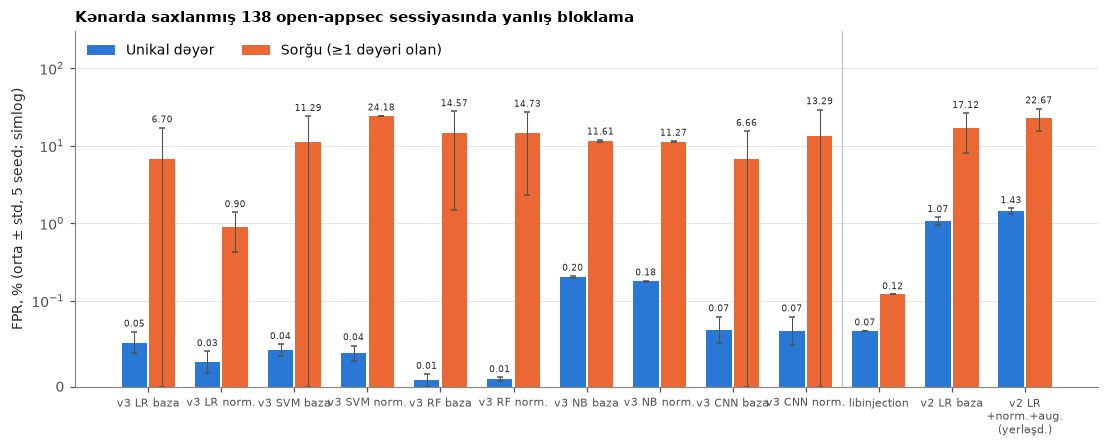

In [10]:
labels = [n.replace("v3-sess: ", "v3 ").replace("v2: ", "v2 ").replace(" (yerləşdirilən)", "\n(yerləşd.)")
          .replace("libinjection 4.0.1", "libinjection").replace(" + norm. + aug.", "\n+norm.+aug.") for n in ORDER]
fig, ax = plt.subplots(figsize=(12, 4.2))
x, w = np.arange(len(ORDER)), 0.38
for i, (m, lab, col) in enumerate([("fpr_value_unique", "Unikal dəyər", "#2a78d6"),
                                    ("fpr_request", "Sorğu (≥1 dəyəri olan)", "#eb6834")]):
    d = a.xs(m, level="metric").loc[ORDER]
    b = ax.bar(x + (i - 0.5) * w, d["mean"], w - 0.03, yerr=[np.minimum(d["std"].fillna(0), d["mean"]), d["std"].fillna(0)], capsize=2, color=col, label=lab,
               error_kw=dict(elinewidth=0.7, ecolor="#52514e"))
    ax.bar_label(b, fmt="%.2f", fontsize=6, padding=2, color="#2b2b2a")
ax.axvline(len(v3.MODEL_ORDER) - 0.5, color="#c3c2b7", lw=0.8)
ax.set_yscale("symlog", linthresh=0.1)
ax.set_ylim(0, 300)                                     # legend və yazılar üçün yer
ax.set_xticks(x, labels, fontsize=7, rotation=0)
ax.set_ylabel("FPR, % (orta ± std, 5 seed; simlog)")
ax.yaxis.grid(True); ax.set_axisbelow(True)
ax.set_title(f"Kənarda saxlanmış {n_hold} open-appsec sessiyasında yanlış bloklama", loc="left")
ax.legend(ncol=2, loc="upper left")
fig.savefig(FIG / "17b_holdout_fpr.png")
plt.show()